# Notebook 21 — CANOE electricity / Atlite technology crosswalk

**Question:** Which generation configurations should produce the weather-dependent
capacity factors paired with CANOE electricity's ATB costs?

Start with CSV file lines **23 (solar)** and **25 (wind_onshore)**, including the header.
Select by stable technology code rather than line position. Run cells in order with the
GeoCANOE `.venv` kernel. This notebook reads the sister repository without importing its
execution modules, calling APIs, or modifying either model database.

Notebook 20 supplies a cached ERA5 pilot. This notebook audits technology assumptions and
compares local conversions. It makes no CDS requests. Section 8a retrieves one pinned
ATB summary CSV only if its verified local cache is absent. National Bronze
acquisition, bounded request batches, retries and cache orchestration belong to Notebook 22.


## 1. Locate the two repositories and inspect the kernel


In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import sys
import tomllib

import atlite
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
from IPython.display import display
from atlite.resource import get_windturbineconfig, get_solarpanelconfig

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/geocanoe').is_dir() and (p / 'pyproject.toml').exists()), None)
assert ROOT is not None, 'Start from the GeoCANOE repository or its notebooks directory.'
SISTER = ROOT.parent / 'canoe-electricity-main'  # change this if stored elsewhere
GENERATOR_CSV = SISTER / 'input_files/generator_technologies.csv'
PARAMS_TOML = SISTER / 'input_files/params.toml'
assert GENERATOR_CSV.is_file() and PARAMS_TOML.is_file(), 'Check SISTER path.'
OUT = ROOT / 'data_files/processed/renewables/technology_crosswalk'
OUT.mkdir(parents=True, exist_ok=True)
VERSIONS = {name: version(name) for name in ['atlite', 'xarray', 'numpy', 'pandas', 'geopandas']}
print('Kernel:', sys.executable)
print('GeoCANOE:', ROOT)
print('Read-only sister repository:', SISTER)
display(pd.Series(VERSIONS, name='version'))


Kernel: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\.venv\Scripts\python.exe
GeoCANOE: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace
Read-only sister repository: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\canoe-electricity-main


atlite          0.7.0
xarray       2026.9.0
numpy           2.3.1
pandas          2.3.1
geopandas       1.1.3
Name: version, dtype: object

## 2. Read the exact source rows and shared economic settings
`atb_min_year` is a minimum data-selection year, not the ATB edition or turbine vintage.
`new_cap_batches` is the number of new-capacity resource bins, not a turbine rating.
Wind Class 7 and PV Class 3 are ATB resource categories; neither establishes a Canadian
region's ERA5-derived resource quality.


In [2]:
generators = pd.read_csv(GENERATOR_CSV).set_index('code', verify_integrity=True)
selected = generators.loc[['solar', 'wind_onshore']].copy()
params = tomllib.loads(PARAMS_TOML.read_text(encoding='utf-8'))
columns = ['base_tech', 'description', 'include_new', 'atb_display_name', 'atb_scenario',
           'atb_min_year', 'new_cap_batches', 'in_comm', 'out_comm']
display(selected[columns])
economics = {
    'atb_edition': params['atb']['year'],
    'atb_case': params['atb']['core_metric_case'],
    'investment_metric': params['atb']['cost_invest_metric'],
    'source_currency': params['atb']['currency'],
    'source_currency_year': params['atb']['currency_year'],
    'final_currency': params['final_currency'],
    'final_currency_year': params['final_currency_year'],
    'weather_year': params['weather_year'], 'model_timezone': params['timezone'],
    'solar_annual_degradation': params['solar_degradation']['rate'],
}
display(pd.Series(economics, name='sister_repository_setting'))
display(pd.Series(params['new_wind_techs'], name='wind_class_cost_mapping'))


,base_tech,description,include_new,atb_display_name,atb_scenario,atb_min_year,new_cap_batches,in_comm,out_comm
code,,,,,,,,,
solar,E_SOL_PV,utility-scale solar photovoltaic generation,True,Utility PV - Class 3,Moderate,2022,5.0,ethos,elc_tx
wind_onshore,E_WND_ON,onshore wind generation,True,Land-Based Wind - Class 7 - Technology 1,Moderate,2022,13.0,ethos,elc_tx


atb_edition                   2024
atb_case                    Market
investment_metric              OCC
source_currency                USD
source_currency_year          2021
final_currency                 CAD
final_currency_year           2020
weather_year                  2018
model_timezone                 EST
solar_annual_degradation    0.0085
Name: sister_repository_setting, dtype: object

t1    Land-Based Wind - Class 7 - Technology 1
t2    Land-Based Wind - Class 8 - Technology 2
t3    Land-Based Wind - Class 9 - Technology 3
Name: wind_class_cost_mapping, dtype: object

## 3. Trace the active wind/solar integration without executing it
The `include_new_wind_solar` path in `new_wind_solar.py` uses Ontario resource files,
cluster capacities and spur costs. It is more specific than the generic generator row.
Wind costs are weighted by T1/T2/T3 capacity fractions; performance is scaled relative to
2030. Solar performance is scaled relative to 2022. The solar notes in that module mention
wind/2030, but the implemented solar denominator is 2022; use the actual code as evidence.

`utils._initialise_atb()` filters the selected case and a 20-year cost recovery period.
`utils.data_year()` uses period-end cost years for new vintages (vintage + period step).
For reproducibility, snippets below expose current source line numbers rather than importing
the sibling package, whose setup and database operations are outside this notebook's scope.


In [3]:
VRE_SOURCE = SISTER / 'canoe_electricity/new_wind_solar.py'
UTILS_SOURCE = SISTER / 'canoe_electricity/utils.py'
needles = ["wind_dir =", "solar_dir =", "class_data =", "Fraction T",
           "df_cf_index[cluster] = df_cf_index", "cf_index /=", 'cf.clip',
           'deg_rate =', 'core_metric_case', "period_or_vintage + config.period_step"]
for path in [VRE_SOURCE, UTILS_SOURCE]:
    print(f'\n{path.relative_to(SISTER)}')
    for line_no, line in enumerate(path.read_text(encoding='utf-8').splitlines(), 1):
        if not line.lstrip().startswith('#') and any(token in line for token in needles):
            print(f'{line_no}: {line.strip()}')
composition_path = SISTER / 'provincial_data/on/new_wind/Cluster Composition.csv'
composition = pd.read_csv(composition_path, index_col=0)
fractions = composition[['Fraction T1', 'Fraction T2', 'Fraction T3']]
assert np.allclose(fractions.sum(axis=1), 1, atol=1e-5)
display(composition.head())
print('Cluster count:', len(composition))



canoe_electricity\new_wind_solar.py
46: wind_dir = os.path.realpath(os.path.dirname(__name__)) + f"/provincial_data/on/new_wind/" # TODO other provinces data
57: class_data = {'t1': dict(), 't2': dict(), 't3': dict()}
90: df_cf_index[cluster] = df_cf_index[cluster] / df_cf_index[cluster]['2030'] # index to ATB wind base year, 2030
197: cf = cf.clip(0, 1)
257: solar_dir = os.path.realpath(os.path.dirname(__name__)) + f"/provincial_data/on/new_solar/" # TODO other provinces
287: cf_index /= cf_index['2022'] # index to base year for solar, 2022
326: deg_rate = config.solar_degradation.rate
384: cf = cf.clip(0, 1)

canoe_electricity\utils.py
70: df_atb = df_atb.loc[(df_atb['core_metric_case']==config.atb.core_metric_case) & (df_atb['crpyears'].astype(int)==20)]
82: return period_or_vintage + config.period_step
95: note = f"{tech_config.atb_display_name} - {tech_config.atb_scenario} - {config.atb.core_metric_case}"


,Maximum Capacity (MW),Total Capacity T1,Total Capacity T2,Total Capacity T3,Fraction T1,Fraction T2,Fraction T3
Wind Resource Bins,,,,,,,
22,704.169800,704.169800,0.0,0.0,1.0,0.0,0.0
24,1874.139645,1874.139645,0.0,0.0,1.0,0.0,0.0
25,1865.443244,1865.443244,0.0,0.0,1.0,0.0,0.0
26,3657.693836,3657.693836,0.0,0.0,1.0,0.0,0.0
27,9919.092037,9919.092037,0.0,0.0,1.0,0.0,0.0


Cluster count: 13


## 4. ATB targets and evidence boundaries
The linked **2024b wind documentation** describes T1 as 6 MW / 170 m rotor / 115 m hub;
T2 as 8.3 MW / 196 m / 130 m; T3 as 3.3 MW / 148 m / 100 m. Treat these as documented
targets and verify against the sister repository's pinned 2024 v3.0.0 workbook before an
exact production mapping. Rating and hub height alone do not determine a power curve.

The solar target has single-axis tracking, ILR = 1.34 and AC-rated capacity. The PV cost
reference includes bifacial characteristics and lifetime-average performance assumptions.
Our simple Atlite panel comparison below is not a full reproduction of that reference.

Sources:
- [ATB 2024b wind characteristics and classes](https://atb.nlr.gov/electricity/2024b/land-based_wind)
- [ATB 2024 utility-scale PV](https://atb.nlr.gov/electricity/2024/utility-scale_pv)
- [Atlite conversion implementation](https://github.com/PyPSA/atlite/blob/master/atlite/convert.py)
- [Atlite solar panel implementation](https://github.com/PyPSA/atlite/blob/master/atlite/pv/solar_panel_model.py)

The sister repo maps T1/T2/T3 to resource classes 7/8/9. Those are economic/reference
selectors, not instructions to label all Canadian cells with those resource classes.


In [4]:
wind_targets = pd.DataFrame([
    {'technology': 't1', 'rating_mw': 6.0, 'rotor_diameter_m': 170., 'hub_height_m': 115.},
    {'technology': 't2', 'rating_mw': 8.3, 'rotor_diameter_m': 196., 'hub_height_m': 130.},
    {'technology': 't3', 'rating_mw': 3.3, 'rotor_diameter_m': 148., 'hub_height_m': 100.},
]).set_index('technology')
wind_targets['atb_display_name'] = pd.Series(params['new_wind_techs'])
wind_targets['specific_power_w_m2'] = wind_targets.rating_mw * 1e6 / (np.pi * (wind_targets.rotor_diameter_m / 2)**2)
wind_targets['source'] = 'ATB 2024b documentation; reconcile with pinned 2024 v3 workbook'
display(wind_targets)


,rating_mw,rotor_diameter_m,hub_height_m,atb_display_name,specific_power_w_m2,source
technology,,,,,,
t1,6.0,170.0,115.0,Land-Based Wind - Class 7 - Technology 1,264.340390,ATB 2024b documentation; reconcile with pinned...
t2,8.3,196.0,130.0,Land-Based Wind - Class 8 - Technology 2,275.090801,ATB 2024b documentation; reconcile with pinned...
t3,3.3,148.0,100.0,Land-Based Wind - Class 9 - Technology 3,191.822977,ATB 2024b documentation; reconcile with pinned...


## 5. Inventory installed Atlite turbines and compare candidate power curves
Keep Notebook 20's Vestas turbine as a control and test the bundled onshore ATB 2020
references as **proxies**. They are not assumed to be ATB 2024 T1/T2/T3 equivalents.
Do not manufacture an exact match by changing only a turbine's rating or hub height.
An exact target requires a traceable power curve and validated turbine configuration.


,rating_mw,hub_height_m,source,mapping_status
atlite_name,,,,
Vestas_V112_3MW,3.06,80.0,http://nozebra.ipapercms.dk/Vestas/Communicati...,Control
NREL_ReferenceTurbine_2020ATB_4MW,4.00,110.0,https://nrel.github.io/turbine-models/2020ATB_...,ATB 2020 proxy; not an exact ATB 2024 match
NREL_ReferenceTurbine_2020ATB_5.5MW,5.50,120.0,https://nrel.github.io/turbine-models/2020ATB_...,ATB 2020 proxy; not an exact ATB 2024 match
NREL_ReferenceTurbine_2020ATB_7MW,7.00,175.0,https://nrel.github.io/turbine-models/2020ATB_...,ATB 2020 proxy; not an exact ATB 2024 match


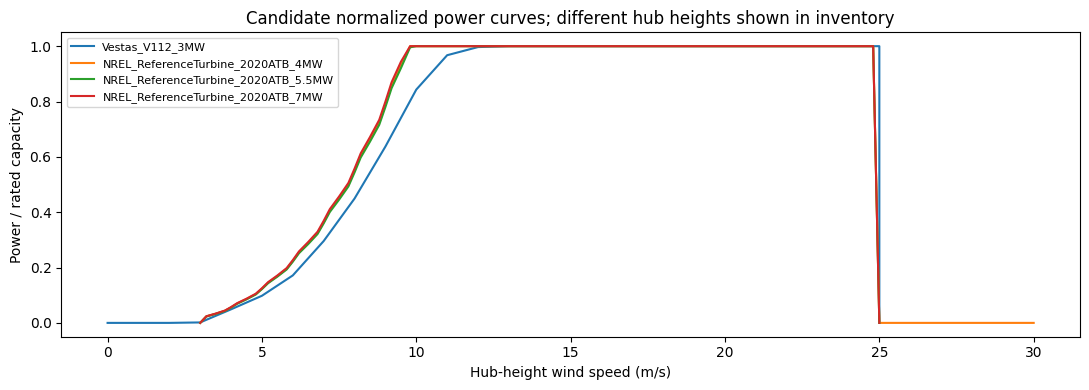

,technology,atlite_name,rating_difference_mw,hub_height_difference_m
0,t1,Vestas_V112_3MW,-2.94,-35.0
1,t2,Vestas_V112_3MW,-5.24,-50.0
2,t3,Vestas_V112_3MW,-0.24,-20.0
3,t1,NREL_ReferenceTurbine_2020ATB_4MW,-2.00,-5.0
4,t2,NREL_ReferenceTurbine_2020ATB_4MW,-4.30,-20.0
5,t3,NREL_ReferenceTurbine_2020ATB_4MW,0.70,10.0
6,t1,NREL_ReferenceTurbine_2020ATB_5.5MW,-0.50,5.0
7,t2,NREL_ReferenceTurbine_2020ATB_5.5MW,-2.80,-10.0
8,t3,NREL_ReferenceTurbine_2020ATB_5.5MW,2.20,20.0
9,t1,NREL_ReferenceTurbine_2020ATB_7MW,1.00,60.0


In [5]:
resource_dir = Path(atlite.__file__).parent / 'resources/windturbine'
WIND_CANDIDATES = [
    'Vestas_V112_3MW',
    'NREL_ReferenceTurbine_2020ATB_4MW',
    'NREL_ReferenceTurbine_2020ATB_5.5MW',
    'NREL_ReferenceTurbine_2020ATB_7MW',
]
inventory = []
for name in WIND_CANDIDATES:
    assert name in atlite.windturbines, f'Missing candidate: {name}'
    config = get_windturbineconfig(name)
    raw = yaml.safe_load((resource_dir / f'{name}.yaml').read_text(encoding='utf-8'))
    inventory.append({'atlite_name': name, 'rating_mw': float(config['P']),
                      'hub_height_m': float(config['hub_height']),
                      'source': raw.get('source', ''),
                      'mapping_status': 'Control' if name.startswith('Vestas') else 'ATB 2020 proxy; not an exact ATB 2024 match'})
inventory = pd.DataFrame(inventory).set_index('atlite_name')
display(inventory)
ax = None
for name in WIND_CANDIDATES:
    config = get_windturbineconfig(name)
    ax = pd.Series(np.array(config['POW']) / config['P'], index=config['V'], name=name).plot(ax=ax, figsize=(11, 4))
ax.set(xlabel='Hub-height wind speed (m/s)', ylabel='Power / rated capacity',
       title='Candidate normalized power curves; different hub heights shown in inventory')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / 'candidate_wind_power_curves.png', dpi=150)
plt.show()
comparison = inventory.reset_index().merge(wind_targets.reset_index(), how='cross', suffixes=('_candidate', '_target'))
comparison['rating_difference_mw'] = comparison.rating_mw_candidate - comparison.rating_mw_target
comparison['hub_height_difference_m'] = comparison.hub_height_m_candidate - comparison.hub_height_m_target
display(comparison[['technology', 'atlite_name', 'rating_difference_mw', 'hub_height_difference_m']])


## 6. Select a prepared Notebook 20 cutout — no download
Set `CUTOUT_PATH` explicitly if more than one cache exists. Selection is deterministic and
never silently chooses the first of multiple weather periods. Missing cache means run
Notebook 20 first. UTC is retained; the sister repository uses EST and a different weather
year, so its profiles are not a direct hour-by-hour validation target for this one-day pilot.


In [6]:
CUTOUT_PATH = None  # or ROOT / 'data_files/raw/era5/atlite_pilot/era5_<identity>.nc'
if CUTOUT_PATH is None:
    caches = sorted((ROOT / 'data_files/raw/era5/atlite_pilot').glob('*.nc'))
    if len(caches) != 1:
        raise ValueError(f'Found {len(caches)} cutouts. Set CUTOUT_PATH to one prepared Notebook 20 cache.')
    CUTOUT_PATH = caches[0]
CUTOUT_PATH = Path(CUTOUT_PATH)
assert CUTOUT_PATH.is_file(), 'Run Notebook 20 first.'
cutout = atlite.Cutout(CUTOUT_PATH)
required = {'wnd100m', 'roughness', 'temperature', 'influx_direct', 'influx_diffuse'}
assert required.issubset(cutout.data.data_vars), 'Cutout is missing prepared features.'
time = pd.DatetimeIndex(cutout.data.time.values)
assert len(time) > 1 and time.is_unique and time.is_monotonic_increasing
assert (np.diff(time.values) == np.timedelta64(1, 'h')).all(), 'Require continuous hourly weather.'
print('Cache:', CUTOUT_PATH)
print('Sample:', time.min(), 'through', time.max(), 'UTC;', len(time), 'hours')


DLL load failed while importing _eccodes: The specified module could not be found.
c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\.venv\Lib\site-packages\xarray\backends\plugins.py:109: RuntimeWarning: Engine 'cfgrib' loading failed:
DLL load failed while importing _eccodes: The specified module could not be found.
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Cache: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\raw\era5\atlite_pilot\era5_373bbff21566.nc
Sample: 2020-06-06 00:00:00 through 2020-06-06 23:00:00 UTC; 24 hours


## 7. Wind sensitivity under identical ERA5 weather
Hold the weather and logarithmic height-extrapolation method fixed. Each candidate uses
its own documented hub height and power curve. No ATB improvement multiplier or additional
fleet-loss adjustment is applied. Results are resource profiles, not calibrated net plant
performance. Equal-weather-cell means below are diagnostics, not eligible-capacity-weighted
regional means or annual CF estimates.


,sample_mean_equal_cell,max_cell_hour,rating_mw,hub_height_m,mapping_status
Vestas_V112_3MW,0.235093,0.991326,3.06,80.0,Control
NREL_ReferenceTurbine_2020ATB_4MW,0.337795,1.000000,4.00,110.0,ATB 2020 proxy; not an exact ATB 2024 match
NREL_ReferenceTurbine_2020ATB_5.5MW,0.348800,1.000000,5.50,120.0,ATB 2020 proxy; not an exact ATB 2024 match
NREL_ReferenceTurbine_2020ATB_7MW,0.422383,1.000000,7.00,175.0,ATB 2020 proxy; not an exact ATB 2024 match


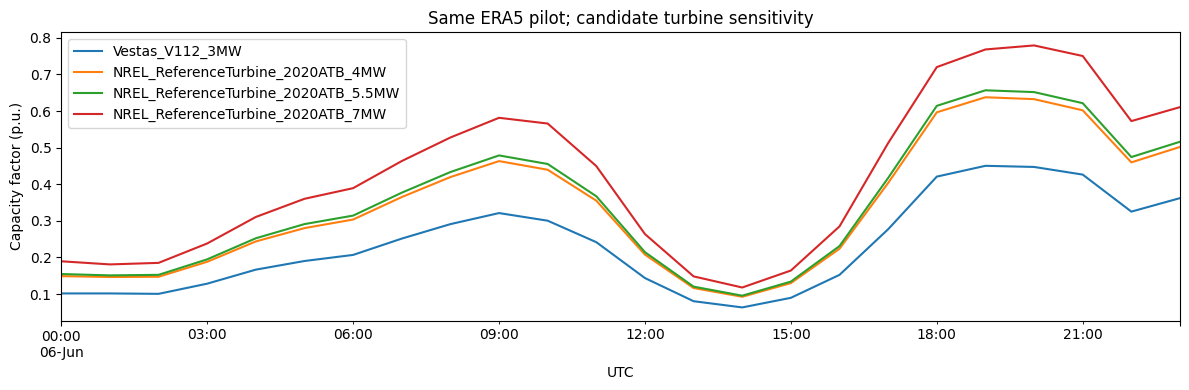

In [7]:
wind_profiles = xr.Dataset({
    name: cutout.wind(turbine=name, interpolation_method='logarithmic', aggregate_time=None,
                      dask_kwargs={'scheduler': 'single-threaded'})
    for name in WIND_CANDIDATES
})
for name, da in wind_profiles.data_vars.items():
    assert np.isfinite(da.values).all() and float(da.min()) >= 0 and float(da.max()) <= 1 + 1e-8, name
wind_hourly = wind_profiles.mean(['x', 'y']).to_dataframe()
wind_hourly.index.name = 'time_utc'
wind_stats = pd.DataFrame({name: {'sample_mean_equal_cell': float(da.mean()), 'max_cell_hour': float(da.max())}
                           for name, da in wind_profiles.data_vars.items()}).T
display(wind_stats.join(inventory[['rating_mw', 'hub_height_m', 'mapping_status']]))
ax = wind_hourly.plot(figsize=(12, 4), ylabel='Capacity factor (p.u.)', title='Same ERA5 pilot; candidate turbine sensitivity')
ax.set_xlabel('UTC')
plt.tight_layout()
plt.savefig(OUT / 'wind_candidate_hourly_comparison.png', dpi=150)
plt.show()


## 8. Solar: tracking and an explicit AC capacity basis
Atlite's CSi panel uses an inverter-efficiency parameter but does not by itself implement
the ATB plant's complete ILR, bifacial, shading, backtracking and loss assumptions.
For this experiment set panel inverter efficiency to **1**, then apply a stated inverter
efficiency once. Interpret output as power per module DC nameplate, multiply by ILR and
inverter efficiency, then cap at the inverter's AC nameplate:

`AC capacity factor = min(module_specific_output × ILR × inverter_efficiency, 1)`.

This is a simplified constant-efficiency inverter model, not a validated ATB replication.
Fixed tilt and a tracking control both use ILR=1 to isolate tracking; the ATB-oriented
tracking proxy uses ILR=1.34 to examine inverter sizing separately. No extra loss/degradation
factor or bifacial gain is silently applied. A north-south horizontal tracker is represented
by slope=0, azimuth=180, tracking='horizontal' in Atlite. Compare on a common AC basis.


Bundled CSi inverter efficiency: 0.9


,sample_mean_ac_equal_cell,cell_hours_clipped,mean_clipping_reduction_pu_ac
case,,,
fixed_tilt_control,0.254129,0,0.000000
single_axis_ilr1_control,0.367723,0,0.000000
single_axis_atb_proxy,0.483772,608,0.008978


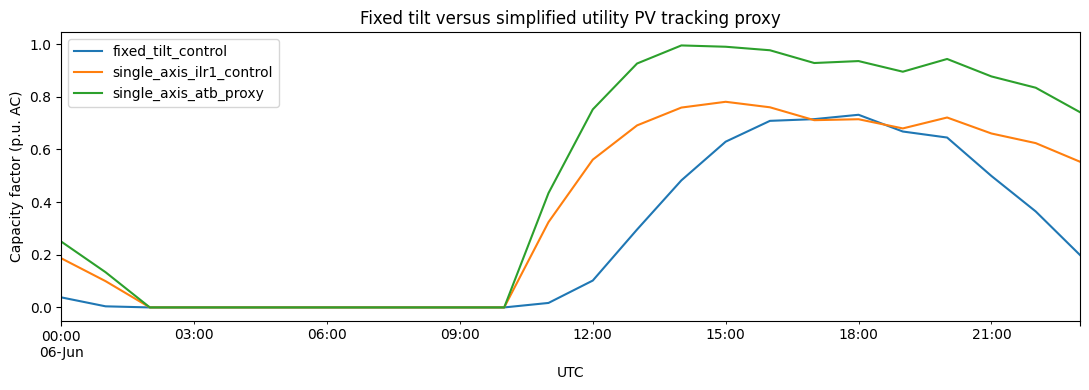

In [8]:
panel = dict(get_solarpanelconfig('CSi'))
print('Bundled CSi inverter efficiency:', panel.get('inverter_efficiency', 1.0))
panel['inverter_efficiency'] = 1.0
PV_CASES = {
    'fixed_tilt_control': {'orientation': {'slope': 35., 'azimuth': 180.}, 'tracking': None, 'ilr': 1.0},
    'single_axis_ilr1_control': {'orientation': {'slope': 0., 'azimuth': 180.}, 'tracking': 'horizontal', 'ilr': 1.0},
    'single_axis_atb_proxy': {'orientation': {'slope': 0., 'azimuth': 180.}, 'tracking': 'horizontal', 'ilr': 1.34},
}
INVERTER_EFFICIENCY = 0.96  # stated experiment assumption, not an inferred sister-repo setting
solar_profiles = xr.Dataset()
solar_diagnostics = []
for name, case in PV_CASES.items():
    module_output = cutout.pv(panel=panel, orientation=case['orientation'], tracking=case['tracking'],
                             aggregate_time=None, dask_kwargs={'scheduler': 'single-threaded'})
    assert np.isfinite(module_output.values).all() and float(module_output.min()) >= 0
    unclipped_ac = module_output * case['ilr'] * INVERTER_EFFICIENCY
    solar_profiles[name] = unclipped_ac.clip(max=1)
    solar_profiles[name].attrs.update(units='p.u. AC', ilr=case['ilr'], inverter_efficiency=INVERTER_EFFICIENCY)
    solar_diagnostics.append({'case': name, 'sample_mean_ac_equal_cell': float(solar_profiles[name].mean()),
                              'cell_hours_clipped': int((unclipped_ac > 1).sum()),
                              'mean_clipping_reduction_pu_ac': float((unclipped_ac - solar_profiles[name]).mean())})
solar_stats = pd.DataFrame(solar_diagnostics).set_index('case')
display(solar_stats)
solar_hourly = solar_profiles.mean(['x', 'y']).to_dataframe()
solar_hourly.index.name = 'time_utc'
ax = solar_hourly.plot(figsize=(11, 4), ylabel='Capacity factor (p.u. AC)', title='Fixed tilt versus simplified utility PV tracking proxy')
ax.set_xlabel('UTC')
plt.tight_layout()
plt.savefig(OUT / 'solar_tracking_ac_comparison.png', dpi=150)
plt.show()


## 8a. Acquire the missing ATB baseline once

This retrieves the **2024 v3.0.0** full summary CSV referenced by CANOE (about 99 MB).
It preserves the original bytes under `data_files/raw/atb/2024/v3.0.0/`, with source URL,
retrieval time, checksum and HTTP metadata. Reruns verify and reuse the cache without
a network request. One sequential download is used; no scraping or parallel requests.

Keep this edition fixed for the baseline comparison. A different edition needs its own
cache and explicit technology/cost-setting reconciliation. The loaded-data identity and
CANOE reference settings are recorded separately in the analysis manifest.

[Official ATB 2024 data download page](https://atb.nlr.gov/electricity/2024/data).


In [9]:
from pathlib import Path
import csv
import hashlib
import json
import os
from datetime import datetime, timezone
import requests

ATB_EDITION = 2024
ATB_REVISION = 'v3.0.0'
ATB_URL = f'https://oedi-data-lake.s3.amazonaws.com/ATB/electricity/csv/{ATB_EDITION}/{ATB_REVISION}/ATBe.csv'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/geocanoe').is_dir())
ATB_DIR = ROOT / 'data_files/raw/atb' / str(ATB_EDITION) / ATB_REVISION
ATB_LOCAL_CSV = ATB_DIR / 'ATBe.csv'
ATB_MANIFEST_PATH = ATB_DIR / 'acquisition_manifest.json'
ATB_DIR.mkdir(parents=True, exist_ok=True)

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

if ATB_LOCAL_CSV.exists():
    if not ATB_MANIFEST_PATH.exists():
        raise ValueError('Existing ATBe.csv has no acquisition manifest; inspect before reuse.')
    ATB_ACQUISITION = json.loads(ATB_MANIFEST_PATH.read_text(encoding='utf-8'))
    assert ATB_ACQUISITION['source_url'] == ATB_URL
    assert ATB_ACQUISITION['sha256'] == file_sha256(ATB_LOCAL_CSV), 'Cached ATB checksum mismatch.'
    print('Reusing verified ATB cache:', ATB_LOCAL_CSV)
else:
    temporary = ATB_LOCAL_CSV.with_suffix('.csv.part')
    try:
        print('Downloading one ATB summary CSV:', ATB_URL, flush=True)
        with requests.get(ATB_URL, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            with temporary.open('wb') as stream:
                for block in response.iter_content(chunk_size=1024 * 1024):
                    if block:
                        stream.write(block)
            expected = response.headers.get('Content-Length')
            if expected is not None:
                assert temporary.stat().st_size == int(expected), 'Incomplete ATB download.'
            with temporary.open(encoding='utf-8-sig', newline='') as stream:
                header = next(csv.reader(stream))
            assert {'display_name', 'scenario', 'core_metric_parameter', 'value'}.issubset(header), 'Unexpected ATB CSV schema.'
            ATB_ACQUISITION = {
                'dataset': 'Electricity Annual Technology Baseline summary CSV',
                'edition': ATB_EDITION, 'revision': ATB_REVISION, 'source_url': ATB_URL,
                'retrieved_utc': datetime.now(timezone.utc).isoformat(),
                'sha256': file_sha256(temporary), 'bytes': temporary.stat().st_size,
                'etag': response.headers.get('ETag'),
                'last_modified': response.headers.get('Last-Modified'),
            }
        os.replace(temporary, ATB_LOCAL_CSV)
        ATB_MANIFEST_PATH.write_text(json.dumps(ATB_ACQUISITION, indent=2)+'\n', encoding='utf-8')
    finally:
        temporary.unlink(missing_ok=True)
    print('Cached ATB:', ATB_LOCAL_CSV)
    print('Bytes:', ATB_ACQUISITION['bytes'])


Reusing verified ATB cache: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\raw\atb\2024\v3.0.0\ATBe.csv


## 9. Cached ATB cost/performance audit
The preceding acquisition cell supplies the pinned ATB 2024 v3.0.0 CSV. This analysis cell makes no network requests.
This reproduces the sister repo's selectors (display name, Moderate, Market, CRP=20),
including T2/T3 overrides, and inspects OCC, fixed O&M and CF rather than calling its
database-writing aggregation functions. Missing/duplicate selectors fail visibly.
Raw costs retain **source currency and units**; this notebook does not apply CAD conversion.
No absolute U.S. resource-class CF is substituted for Canadian ERA5 profiles.


In [10]:
ATB_LOCAL_CSV = ATB_DIR / 'ATBe.csv'  # provided by section 8a
atb_audit = pd.DataFrame()
if ATB_LOCAL_CSV is None:
    print('Cost values not loaded: set ATB_LOCAL_CSV to an existing cached ATBe.csv.')
else:
    atb_path = Path(ATB_LOCAL_CSV)
    assert atb_path.is_file(), 'A local CSV is required.'
    atb = pd.read_csv(atb_path, dtype=str)
    required_columns = {'display_name', 'scenario', 'core_metric_case', 'crpyears',
                        'core_metric_parameter', 'core_metric_variable', 'value'}
    assert required_columns.issubset(atb.columns), 'Expected full ATBe schema.'
    selectors = [(row.atb_display_name, row.atb_scenario) for _,row in selected.iterrows()]
    selectors.extend((name, selected.loc['wind_onshore', 'atb_scenario']) for name in params['new_wind_techs'].values())
    selectors = sorted(set(selectors))
    records = []
    for display_name, scenario in selectors:
        subset = atb.loc[(atb.display_name == display_name) & (atb.scenario == scenario)
                         & (atb.core_metric_case == params['atb']['core_metric_case'])
                         & (pd.to_numeric(atb.crpyears) == 20)
                         & atb.core_metric_parameter.isin([params['atb']['cost_invest_metric'], 'Fixed O&M', 'CF'])].copy()
        assert not subset.empty, f'No ATB rows: {display_name}, {scenario}'
        assert not subset.duplicated(['core_metric_parameter', 'core_metric_variable']).any(), 'Ambiguous ATB rows'
        assert set(subset.core_metric_parameter) == {params['atb']['cost_invest_metric'], 'Fixed O&M', 'CF'}
        records.append(subset)
    atb_audit = pd.concat(records, ignore_index=True)
    atb_audit['value'] = pd.to_numeric(atb_audit['value'])
    display(atb_audit[['display_name', 'scenario', 'core_metric_parameter', 'core_metric_variable', 'value']].head(20))


,display_name,scenario,core_metric_parameter,core_metric_variable,value
0,Land-Based Wind - Class 7 - Technology 1,Moderate,CF,2027,0.393163
1,Land-Based Wind - Class 7 - Technology 1,Moderate,OCC,2027,1357.792700
2,Land-Based Wind - Class 7 - Technology 1,Moderate,Fixed O&M,2027,30.456001
3,Land-Based Wind - Class 7 - Technology 1,Moderate,CF,2028,0.396050
4,Land-Based Wind - Class 7 - Technology 1,Moderate,OCC,2028,1335.040052
5,Land-Based Wind - Class 7 - Technology 1,Moderate,Fixed O&M,2028,30.058592
6,Land-Based Wind - Class 7 - Technology 1,Moderate,CF,2029,0.398937
7,Land-Based Wind - Class 7 - Technology 1,Moderate,OCC,2029,1312.287405
8,Land-Based Wind - Class 7 - Technology 1,Moderate,Fixed O&M,2029,29.661182
9,Land-Based Wind - Class 7 - Technology 1,Moderate,CF,2022,0.378727


## 10. Crosswalk conclusions and decisions before production
The output is deliberately **provisional**. Select exact wind curves only after retrieving
traceable T1/T2/T3 performance configurations consistent with the pinned cost edition.
Until then the bundled curves remain sensitivity cases. A resource class is not a unique
turbine identifier; matching rating alone is insufficient.

For PV, single-axis tracking and explicit AC normalization improve conceptual compatibility,
but bifacial response, backtracking, losses and degradation still need reconciliation.

Choose one documented technology-improvement strategy: either simulate changing physical
configurations or apply an ATB improvement trajectory to a fixed baseline. If combining them,
apply only residual improvements not already in the physical model. The same care applies
to lifetime-average ATB PV performance versus explicit annual degradation in CANOE.

The sister repo's 2018/EST and this pilot's 2020/UTC are distinct. Keep weather year,
technology reference year, ATB edition, model vintage and dollar year as separate fields.
One day cannot determine annual resource classes, select national turbines or establish LCOE.

**Update:** Sections 12–17 below resolve the physical T1/T2/T3 archive mapping;
this section records the earlier proxy experiment. Net-performance validation remains open.


In [11]:
crosswalk = selected[columns].copy()
crosswalk['atb_edition'] = params['atb']['year']
crosswalk['atb_case'] = params['atb']['core_metric_case']
crosswalk['status'] = ['Provisional AC tracking proxy; bifacial/loss/degradation reconciliation pending',
                       'Exact 2024 turbine curves unresolved; ATB 2020 proxies only']
crosswalk['atlite_experiment'] = ['CSi, horizontal tracking, ILR 1.34, explicit 0.96 inverter efficiency',
                                 '; '.join(WIND_CANDIDATES[1:])]
crosswalk['production_ready'] = False
display(crosswalk[['base_tech', 'atb_display_name', 'atlite_experiment', 'status', 'production_ready']])


,base_tech,atb_display_name,atlite_experiment,status,production_ready
code,,,,,
solar,E_SOL_PV,Utility PV - Class 3,"CSi, horizontal tracking, ILR 1.34, explicit 0...",Provisional AC tracking proxy; bifacial/loss/d...,False
wind_onshore,E_WND_ON,Land-Based Wind - Class 7 - Technology 1,NREL_ReferenceTurbine_2020ATB_4MW; NREL_Refere...,Exact 2024 turbine curves unresolved; ATB 2020...,False


## 11. Export audit products and provenance
Outputs remain separate from production Silver/Gold. No sister-repo files or cost tables are modified.


In [12]:
crosswalk.to_csv(OUT / 'technology_crosswalk.csv')
wind_targets.to_csv(OUT / 'wind_documentation_targets.csv')
inventory.to_csv(OUT / 'atlite_wind_candidates.csv')
comparison.to_csv(OUT / 'wind_candidate_target_differences.csv', index=False)
wind_stats.to_csv(OUT / 'wind_sample_statistics.csv')
solar_stats.to_csv(OUT / 'solar_sample_statistics.csv')
wind_hourly.to_csv(OUT / 'wind_hourly_equal_cell_diagnostic.csv')
solar_hourly.to_csv(OUT / 'solar_hourly_equal_cell_ac_diagnostic.csv')
wind_profiles.to_netcdf(OUT / 'wind_candidate_hourly_profiles.nc')
solar_profiles.to_netcdf(OUT / 'solar_case_hourly_ac_profiles.nc')
if not atb_audit.empty:
    atb_audit.to_csv(OUT / 'cached_atb_selection_audit.csv', index=False)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

sources = [GENERATOR_CSV, PARAMS_TOML, VRE_SOURCE, UTILS_SOURCE, composition_path, CUTOUT_PATH]
sources.extend(resource_dir / f'{name}.yaml' for name in WIND_CANDIDATES)
sources.append(Path(atlite.__file__).parent / 'resources/solarpanel/CSi.yaml')
if ATB_LOCAL_CSV is not None:
    sources.append(Path(ATB_LOCAL_CSV))
    sources.append(ATB_MANIFEST_PATH)
manifest = {
    'created_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'versions': VERSIONS,
    'source_sha256': {str(path): sha256(path) for path in sources},
    'canoe_reference_economics': economics,
    'canoe_reference_atb_url': params['atb']['url'],
    'loaded_atb': ATB_ACQUISITION if ATB_LOCAL_CSV is not None else None,
    'wind_candidates': WIND_CANDIDATES, 'wind_interpolation': 'logarithmic',
    'pv_cases': PV_CASES, 'inverter_efficiency': INVERTER_EFFICIENCY,
    'weather_start_utc': time.min().isoformat(), 'weather_end_utc': time.max().isoformat(),
    'hours': len(time), 'spatial_summary': 'equal weather-cell diagnostic',
    'applied_atb_cf_multiplier': False, 'additional_fleet_losses_applied': False,
    'production_ready': False,
    'open_items': ['Exact pinned-edition T1/T2/T3 curves', 'PV bifacial/backtracking/loss/degradation consistency',
                   'Regional capacity weighting', 'Multi-year validation', 'Currency/unit integration'],
}
(OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Saved crosswalk audit:', OUT)


Saved crosswalk audit: c:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\processed\renewables\technology_crosswalk


## 12. Resolve the wind curves and PV assumptions
The preceding comparisons are retained as the original ATB 2020 proxy experiment.
This extension adds official **2023 NREL Bespoke T1/T2/T3 reference curves**, whose
metadata match the 2024 ATB technology dimensions. This resolves the physical curve
mapping; it does not establish net plant performance or reproduce Canadian observations.

Sources are pinned to the official turbine archive commit
`e9e4ccc6a87f50c0c65d236154a2897e752c47c9` and the existing ATB **2024 v3.0.0** workbook.
Archive metadata explicitly identify `turbine_class`, rating, rotor diameter and hub height.
The pinned workbook confirms Class 7/T1, Class 8/T2 and Class 9/T3 in
`Land-Based Wind!K20:L22`. The later 2024b web documentation supplies the physical target
dimensions; the archive specs independently match them.

- [Official turbine archive](https://github.com/NatLabRockies/turbine-models)
- [Pinned T1 metadata](https://github.com/NatLabRockies/turbine-models/blob/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/specs/Onshore/2023NREL_Bespoke_6MW_170.yaml)
- [Pinned T2 metadata](https://github.com/NatLabRockies/turbine-models/blob/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/specs/Onshore/2023NREL_Bespoke_8.3MW_196.yaml)
- [Pinned T3 metadata](https://github.com/NatLabRockies/turbine-models/blob/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/specs/Onshore/2023NREL_Bespoke_3.3MW_148.yaml)

Run the earlier cells first. The new sections write to a separate `reconciled/` output
directory, preserving the original proxy experiment and its saved notebook outputs.


In [ ]:
import requests
import os
from openpyxl import load_workbook  # read-only inspection; never edit the source workbook

EVIDENCE = ROOT / 'data_files/raw/atb/2024/v3.0.0/technology_evidence'
RECONCILED = OUT / 'reconciled'
EVIDENCE.mkdir(parents=True, exist_ok=True)
RECONCILED.mkdir(parents=True, exist_ok=True)
ARCHIVE_COMMIT = 'e9e4ccc6a87f50c0c65d236154a2897e752c47c9'
EVIDENCE_SOURCES = {'2024_v3_Workbook.xlsx': {'url': 'https://data.openei.org/files/6006/2024_v3_Workbook.xlsx', 'sha256': '34316344383535a8bf9eb220bc54282cff75bcbc332a38e8c10a17c487dc8e46'}, '2023NREL_Bespoke_6MW_170.csv': {'url': 'https://raw.githubusercontent.com/NatLabRockies/turbine-models/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/data/Onshore/2023NREL_Bespoke_6MW_170.csv', 'sha256': '44ebbbc280ab71f47d81d93cb85e1f10b68b920f21b442d1f33a48da9ea0f4ca'}, '2023NREL_Bespoke_6MW_170.yaml': {'url': 'https://raw.githubusercontent.com/NatLabRockies/turbine-models/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/specs/Onshore/2023NREL_Bespoke_6MW_170.yaml', 'sha256': 'd4af2bd7c123a702cee34e183a93550c3a5966e61068de9df2a02f45e5ec720e'}, '2023NREL_Bespoke_8.3MW_196.csv': {'url': 'https://raw.githubusercontent.com/NatLabRockies/turbine-models/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/data/Onshore/2023NREL_Bespoke_8.3MW_196.csv', 'sha256': '3bc5fc23e8648f5958b62c27796c74ffd92996d94cb90d19ddb97e84ccedd171'}, '2023NREL_Bespoke_8.3MW_196.yaml': {'url': 'https://raw.githubusercontent.com/NatLabRockies/turbine-models/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/specs/Onshore/2023NREL_Bespoke_8.3MW_196.yaml', 'sha256': 'b143754636c3fea87d94b39c40da0774ccdd930b1cb226285edfb26d04cad49c'}, '2023NREL_Bespoke_3.3MW_148.csv': {'url': 'https://raw.githubusercontent.com/NatLabRockies/turbine-models/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/data/Onshore/2023NREL_Bespoke_3.3MW_148.csv', 'sha256': 'dfae1cbab3d9f0cbec7e76fbba5ed0d0fa34fd06d056b1b5944f55856c9949ba'}, '2023NREL_Bespoke_3.3MW_148.yaml': {'url': 'https://raw.githubusercontent.com/NatLabRockies/turbine-models/e9e4ccc6a87f50c0c65d236154a2897e752c47c9/turbine_models/specs/Onshore/2023NREL_Bespoke_3.3MW_148.yaml', 'sha256': 'a1a4eff50829f847889b0ae43a1d65346b639d88ceb71ccbaabca4215838edfe'}}

def ensure_evidence(name, record):
    destination = EVIDENCE / name
    if destination.exists():
        assert sha256(destination) == record['sha256'], f'Cached evidence changed: {name}'
        return
    temporary = destination.with_suffix(destination.suffix + '.part')
    try:
        print('Retrieving one pinned source:', name, flush=True)
        with requests.get(record['url'], stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            with temporary.open('wb') as stream:
                for block in response.iter_content(chunk_size=1024 * 1024):
                    if block:
                        stream.write(block)
        assert sha256(temporary) == record['sha256'], f'Source checksum changed: {name}'
        os.replace(temporary, destination)
    finally:
        temporary.unlink(missing_ok=True)

# At most seven sequential requests on a fresh machine; none when cached.
# HTTP errors stop the cell; there is no retry loop or archive-wide scraping.
for name, record in EVIDENCE_SOURCES.items():
    ensure_evidence(name, record)
print('Verified pinned evidence files:', len(EVIDENCE_SOURCES))


## 13. Inspect the pinned workbook and the actual CANOE export path
Keep the **source dollar year** separate from CANOE's configured dollar year. ATB 2024's
workbook and official definitions state 2022 USD; the sister repo config records 2021 USD.
This is a conversion discrepancy to reconcile before importing costs, not a reason to
relabel the raw values. No currency conversion is applied here.

Solar workbook cells `J12:J14` establish tracking and AC cost basis. `M20` states that CF
is averaged over plant life including degradation. CANOE's current solar export applies
an ATB CF ratio but its v4 code explicitly does not apply annual degradation. A loaded
degradation parameter and a descriptive note do not demonstrate that it affects the data.

[Official ATB 2024 definitions: dollar year](https://atb.nlr.gov/electricity/2024/definitions).


In [ ]:
workbook_path = EVIDENCE / '2024_v3_Workbook.xlsx'
workbook = load_workbook(workbook_path, read_only=True, data_only=True)
cell_refs = {
    'Land-Based Wind': ['J10', 'K20', 'L20', 'K21', 'L21', 'K22', 'L22'],
    'Solar - Utility PV': ['J10', 'J12', 'J13', 'J14', 'M20'],
}
workbook_records = []
for sheet, refs in cell_refs.items():
    for ref in refs:
        workbook_records.append({'sheet': sheet, 'cell': ref, 'value': workbook[sheet][ref].value})
workbook.close()
workbook_evidence = pd.DataFrame(workbook_records)
display(workbook_evidence)
wind_cells = workbook_evidence.loc[workbook_evidence.sheet == 'Land-Based Wind'].set_index('cell').value
for i, target in enumerate(['t1', 't2', 't3'], 20):
    assert wind_cells[f'K{i}'] == params['new_wind_techs'][target]
source_dollar_note = str(wind_cells['J10'])
assert '2022 U.S. dollars' in source_dollar_note
SOURCE_DOLLAR_YEAR = 2022
currency_audit = pd.DataFrame([{
    'atb_source_dollar_year': SOURCE_DOLLAR_YEAR,
    'canoe_configured_dollar_year': params['atb']['currency_year'],
    'currency': 'USD', 'conversion_applied': False,
    'status': 'Mismatch: reconcile before cost integration' if SOURCE_DOLLAR_YEAR != params['atb']['currency_year'] else 'Aligned',
}])
display(currency_audit)
vre_lines = VRE_SOURCE.read_text(encoding='utf-8').splitlines()
solar_code_start = next(i for i,line in enumerate(vre_lines) if line.startswith('def aggregate_solar('))
for i,line in enumerate(vre_lines[solar_code_start:], solar_code_start + 1):
    if any(token in line for token in ['deg_rate =', 'degradation not applied', 'cf: pd.Series', 'cf_index /=']):
        print(f'{VRE_SOURCE.name}:{i}: {line.strip()}')


## 14. Import physically matched T1/T2/T3 curves into Atlite
Unit conversion is explicit: archive power is kW, Atlite power is MW. `P` is the YAML
nominal rating, not an inferred maximum. Validate class, rating, rotor and hub against the
targets. These are theoretical reference curves, not measured commercial turbines.

Two declared adapter choices preserve the raw source files:
1. T3 peaks at 3,303 kW versus a nominal 3,300 kW at three tabulated points. Clip those
   points to nominal output and report the change (maximum reduction 3 kW).
2. All three tables end at 25 m/s with nonzero power and leave YAML cut-out unspecified.
   Add a duplicate 25 m/s point with zero output, matching Atlite's cut-out convention.
   This is an explicit shutdown assumption, not confirmed source turbine behaviour.
   Report pilot hours affected; validate shutdown and high-wind behaviour before production.


In [ ]:
MATCHED_MODELS = {
    't1': '2023NREL_Bespoke_6MW_170',
    't2': '2023NREL_Bespoke_8.3MW_196',
    't3': '2023NREL_Bespoke_3.3MW_148',
}
matched_configs = {}
adapter_rows = []
for tech, model in MATCHED_MODELS.items():
    spec = yaml.safe_load((EVIDENCE / f'{model}.yaml').read_text(encoding='utf-8'))
    curve = pd.read_csv(EVIDENCE / f'{model}.csv')
    target = wind_targets.loc[tech]
    assert spec['turbine_class'].lower() == tech
    assert np.isclose(spec['rated_power'] / 1000, target.rating_mw)
    assert np.isclose(spec['rotor_diameter'], target.rotor_diameter_m)
    assert np.isclose(spec['hub_height'], target.hub_height_m)
    speeds = curve['Wind Speed [m/s]'].to_numpy(dtype=float)
    raw_kw = curve['Power [kW]'].to_numpy(dtype=float)
    assert np.isfinite(speeds).all() and np.isfinite(raw_kw).all()
    assert np.all(np.diff(speeds) > 0) and raw_kw.min() >= 0
    rated_kw = float(spec['rated_power'])
    clipped_kw = np.minimum(raw_kw, rated_kw)
    assert np.isclose(speeds.max(), 25) and clipped_kw[-1] > 0
    config = {
        'name': model, 'V': np.r_[speeds, speeds[-1]],
        'POW': np.r_[clipped_kw / 1000, 0.0], 'P': rated_kw / 1000,
        'hub_height': float(spec['hub_height']),
    }
    get_windturbineconfig(config, add_cutout_windspeed=False)
    matched_configs[tech] = config
    adapter_rows.append({
        'technology': tech, 'model': model, 'nominal_rating_mw': rated_kw / 1000,
        'hub_height_m': spec['hub_height'], 'rotor_diameter_m': spec['rotor_diameter'],
        'source_class': spec['turbine_class'], 'curve_type': spec['power_curve_type'],
        'source_peak_kw': float(raw_kw.max()), 'points_above_nominal': int((raw_kw > rated_kw).sum()),
        'max_reduction_kw': float((raw_kw - clipped_kw).max()),
        'assumed_cutout_m_s': float(speeds[-1]), 'physical_mapping_confirmed': True,
        'production_ready': False,
    })
adapter_audit = pd.DataFrame(adapter_rows).set_index('technology')
display(adapter_audit)
fig, ax = plt.subplots(figsize=(10, 4))
for tech, config in matched_configs.items():
    ax.plot(config['V'], config['POW'] / config['P'], label=f"{tech.upper()}: {config['P']:g} MW, hub {config['hub_height']:g} m")
ax.set(xlabel='Hub-height wind speed (m/s)', ylabel='Power / nominal rating', title='Physically matched reference curves with declared adapter choices')
ax.legend()
fig.tight_layout()
fig.savefig(RECONCILED / 'matched_t1_t2_t3_power_curves.png', dpi=150)
plt.show()


## 15. Compare the matched turbines on the same cached ERA5 weather
Compute gross profiles with the source hub heights, without an ATB improvement multiplier.
The shutdown count checks whether the 25 m/s assumption affects this pilot. It does not
validate high-wind behaviour for a full year or national domain.

For a separate net-output sensitivity, apply the documented **2030 Moderate 13.4% plant
loss** once. This is a scenario assumption from the 2024b wind documentation, not a
Canadian calibration or a complete reproduction of ATB CF. Keep gross and net profiles
separate; do not additionally multiply this experiment by CANOE's future CF index.


In [ ]:
from atlite.wind import extrapolate_wind_speed

matched_gross = xr.Dataset()
shutdown_counts = {}
for tech, config in matched_configs.items():
    matched_gross[tech] = cutout.wind(
        turbine=config, add_cutout_windspeed=False, interpolation_method='logarithmic',
        aggregate_time=None, dask_kwargs={'scheduler': 'single-threaded'},
    )
    hub_speed = extrapolate_wind_speed(cutout.data, to_height=config['hub_height'], method='logarithmic')
    shutdown_counts[tech] = int((hub_speed >= 25).sum().compute())
    assert np.isfinite(matched_gross[tech].values).all()
    assert float(matched_gross[tech].min()) >= 0 and float(matched_gross[tech].max()) <= 1 + 1e-8
WIND_PLANT_LOSS = 0.134
matched_net_sensitivity = matched_gross * (1 - WIND_PLANT_LOSS)
matched_stats = pd.DataFrame({tech: {
    'gross_sample_mean_equal_cell': float(matched_gross[tech].mean()),
    'net_sample_mean_loss_sensitivity': float(matched_net_sensitivity[tech].mean()),
    'cell_hours_at_or_above_assumed_cutout': shutdown_counts[tech],
} for tech in matched_configs}).T
display(matched_stats.join(adapter_audit[['nominal_rating_mw', 'hub_height_m']]))
ax = matched_gross.mean(['x', 'y']).to_dataframe().plot(figsize=(11, 4), ylabel='Gross capacity factor', title='T1/T2/T3: identical ERA5 pilot, source hub heights')
ax.set_xlabel('UTC')
plt.tight_layout()
plt.savefig(RECONCILED / 'matched_t1_t2_t3_hourly.png', dpi=150)
plt.show()


## 16. PV assumptions and technology-improvement accounting
The original PV cells already isolate tracking from ILR on an explicit AC basis.
The table below distinguishes what is represented from what still needs calibration.
Do not assume an inverter efficiency of 0.96 recreates all ATB plant losses.

For new first-year Canadian profiles, recommend the tracking/ILR configuration as a
**physical baseline**, with loss and degradation policy resolved separately. Preserve
gross/module-side and delivered-AC outputs when extending the conversion. ATB's absolute
U.S. resource-class CF is a benchmark, not a replacement for ERA5 weather.

The 2024 PV documentation uses lifetime-average CF; the pinned workbook confirms this.
Do not apply a lifetime-average degradation adjustment and then the same explicit ageing
loss again. No additional PV loss or degradation adjustment is introduced by this section.


In [ ]:
pv_reconciliation = pd.DataFrame([
    ['Tracking', 'Single-axis', 'Horizontal tracker in Atlite', 'Partly aligned; geometry/backtracking still to validate'],
    ['Capacity basis', 'AC; ILR 1.34', 'Explicit ILR and AC clipping', 'Aligned basis; simplified inverter model'],
    ['Inverter efficiency', 'Reference assumption 0.96', '0.96 applied once; panel default overridden to 1', 'Explicit; not a full inverter efficiency curve'],
    ['Bifacial response', 'Included in ATB reference', 'No explicit rear-side model', 'Unresolved; do not add an arbitrary gain'],
    ['Shading/backtracking', 'Plant-level modelling assumptions', 'Not explicitly represented in pilot', 'Unresolved'],
    ['Plant losses', 'Included in ATB CF', 'Only explicit inverter/clipping effects in pilot', 'Resolve DC/system loss budget; avoid duplicates'],
    ['Degradation', 'Lifetime-average ATB CF; workbook Solar - Utility PV!M20',
     'No ageing applied; CANOE parameter is not applied in inspected v4 export', 'Choose first-year plus explicit ageing OR lifetime-average representation'],
    ['Cost dollar year', '2022 USD in pinned workbook', 'CANOE config says 2021 USD', 'Resolve before CAD conversion'],
], columns=['assumption', 'reference', 'pilot_or_canoe', 'decision'])
display(pv_reconciliation)

# Show the sister repo's CF trajectory as a separate diagnostic, not a multiplier
# applied to the physically matched wind/PV profiles in this extension.
assert not atb_audit.empty, 'Run section 9 to load the ATB audit first.'
cf_trajectory = atb_audit.loc[atb_audit.core_metric_parameter == 'CF'].copy()
cf_trajectory['projection_year'] = pd.to_numeric(cf_trajectory.core_metric_variable).astype(int)
atb_cf_table = cf_trajectory.pivot(index='projection_year', columns='display_name', values='value').sort_index()
improvement_indices = atb_cf_table.copy()
for name in improvement_indices:
    base_year = 2022 if name == selected.loc['solar', 'atb_display_name'] else 2030
    improvement_indices[name] /= atb_cf_table.loc[base_year, name]
display(improvement_indices.loc[[2022, 2030, 2040, 2050]])
print('These ratios are diagnostic only: none are applied to the extension profiles.')


## 17. Reconciled crosswalk, exports and remaining evidence request
Wind physical mappings are now supported by class-tagged official curve metadata and
matching technology dimensions. They remain subject to declared nominal-rating/shutdown
choices, air-density assumptions, plant losses and Canadian validation.

The sister repo contains Ontario resource summaries and hourly CFs but the inspected
checkout does not contain their original new-wind/new-solar generation notebook. To
establish exact reproducibility with CANOE, the most useful additional evidence is that
**original resource-characterization notebook/configuration**, including turbine curves,
PV geometry/ILR/bifacial assumptions, weather year and loss factors. The `sutubra_vre.year`
setting is not sufficient to establish the source weather year of those precomputed files.

No national acquisition or production database changes occur here. Outputs are separate
from the original proxy experiment; the extension manifest records adapter choices and
source checksums. `production_ready=False` remains until net-performance validation.


In [ ]:
reconciled_crosswalk = crosswalk.copy()
reconciled_crosswalk.loc['wind_onshore', 'atlite_experiment'] = '; '.join(MATCHED_MODELS.values())
reconciled_crosswalk.loc['wind_onshore', 'status'] = 'Physical T1/T2/T3 mapping confirmed; adapter assumptions and net-plant validation pending'
reconciled_crosswalk.loc['solar', 'status'] = 'AC tracking/ILR proxy; bifacial, losses, ageing and cost dollar year pending'
reconciled_crosswalk['atb_source_currency_year'] = SOURCE_DOLLAR_YEAR
reconciled_crosswalk['canoe_configured_currency_year'] = params['atb']['currency_year']
reconciled_crosswalk['production_ready'] = False
display(reconciled_crosswalk[['base_tech', 'atlite_experiment', 'status', 'production_ready']])
reconciled_crosswalk.to_csv(RECONCILED / 'technology_crosswalk_reconciled.csv')
adapter_audit.to_csv(RECONCILED / 'wind_curve_adapter_audit.csv')
matched_stats.to_csv(RECONCILED / 'matched_wind_sample_statistics.csv')
pv_reconciliation.to_csv(RECONCILED / 'pv_assumption_reconciliation.csv', index=False)
currency_audit.to_csv(RECONCILED / 'currency_year_discrepancy.csv', index=False)
workbook_evidence.to_csv(RECONCILED / 'pinned_workbook_evidence.csv', index=False)
improvement_indices.to_csv(RECONCILED / 'unapplied_atb_cf_improvement_indices.csv')
matched_gross.attrs.update(timezone='UTC', interpretation='Gross theoretical wind profiles; declared rating/shutdown adapter')
matched_gross.to_netcdf(RECONCILED / 'matched_wind_gross_hourly.nc')
matched_net_sensitivity.attrs.update(timezone='UTC', plant_loss=WIND_PLANT_LOSS,
                                    interpretation='2030 Moderate plant-loss sensitivity; not calibrated net generation')
matched_net_sensitivity.to_netcdf(RECONCILED / 'matched_wind_net_loss_sensitivity_hourly.nc')
for tech, config in matched_configs.items():
    serializable = {key: value.tolist() if isinstance(value, np.ndarray) else value for key, value in config.items()}
    (RECONCILED / f'{tech}_atlite_adapter.json').write_text(json.dumps(serializable, indent=2), encoding='utf-8')
extension_manifest = {
    'created_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'versions': VERSIONS,
    'archive_commit': ARCHIVE_COMMIT, 'sources': EVIDENCE_SOURCES,
    'atb_acquisition': ATB_ACQUISITION, 'weather_sha256': sha256(CUTOUT_PATH),
    'sister_vre_source_sha256': sha256(VRE_SOURCE), 'sister_params_sha256': sha256(PARAMS_TOML),
    'atb_source_dollar_year': SOURCE_DOLLAR_YEAR,
    'canoe_configured_dollar_year': params['atb']['currency_year'],
    'matched_models': MATCHED_MODELS,
    'power_adapter': 'kW to MW; clip to YAML nominal rating; append duplicate 25 m/s zero-output point',
    'wind_interpolation': 'logarithmic', 'plant_loss_sensitivity': WIND_PLANT_LOSS,
    'atb_cf_improvement_applied': False, 'physical_mapping_confirmed': True,
    'production_ready': False,
    'open_items': ['Confirm shutdown behaviour', 'Net plant loss and air-density validation',
                   'Original CANOE resource generation notebook/configuration',
                   'PV bifacial/backtracking/loss/ageing assumptions', 'Resolve source dollar year mismatch'],
}
(RECONCILED / 'manifest.json').write_text(json.dumps(extension_manifest, indent=2), encoding='utf-8')
print('Saved reconciled analysis:', RECONCILED)


## 18. Trace the original Ontario resource characterization
This is a **read-only lineage audit** of the sister repo's checked-in data. It does not
execute downloaded code or import the sibling aggregation module. The remote-search
snapshot records a bounded inspection, not a claim that the original notebook is unavailable.

The CANOE file history traces `Solar Resource Summary.csv` to the
[15 May 2024 import](https://github.com/CANOE-main/canoe-electricity/commit/414ac257db06cca2e0836d775042a412b645d29c).
That is a file-import date, not a weather year or evidence of which ATB edition generated
the resources. A later cost edition need not be the original resource-characterization edition.

The public `SutubraResearch/LDES-DataPipeline` has separate `main` and `master` branches;
the first is license-only and the second contains an ATB-based model pipeline, but no
identified Ontario wind/PV generation notebook. The inspected Atlite fork's default branch
contains standard examples. These are search leads, not established source workflows.

The snapshot below was checked once during notebook development. Running this cell does
not query GitHub. The CSV diagnostics recompute from the local sister repo.


In [ ]:
import ast

LINEAGE_OUT = RECONCILED / 'resource_lineage'
LINEAGE_OUT.mkdir(parents=True, exist_ok=True)
remote_audit_path = ROOT / 'data_files/raw/canoe_electricity/resource_lineage/remote_source_audit.json'
if remote_audit_path.exists():
    remote_audit = json.loads(remote_audit_path.read_text(encoding='utf-8'))
    display(pd.DataFrame(remote_audit['sources'])[['repository', 'ref', 'finding', 'url']])
else:
    remote_audit = None
    print('Remote-search snapshot not present; local CSV diagnostics can still run.')

ontario = SISTER / 'provincial_data/on'
resource_inputs = {
    'wind_cells': ontario / 'new_wind/Hourly Capacity Factors.csv',
    'wind_clusters': ontario / 'new_wind/Cluster Capacity Factors.csv',
    'wind_summary': ontario / 'new_wind/Resource Summary.csv',
    'wind_mappings': ontario / 'new_wind/Cluster Mappings.csv',
    'wind_composition': ontario / 'new_wind/Cluster Composition.csv',
    'solar_cells': ontario / 'new_solar/Hourly PV Capacity Factors.csv',
    'solar_summary': ontario / 'new_solar/Solar Resource Summary.csv',
}
assert all(path.is_file() for path in resource_inputs.values())
hourly_sources = {key: pd.read_csv(resource_inputs[key], index_col=0)
                  for key in ['wind_cells', 'wind_clusters', 'solar_cells']}
time_audit_rows = []
for key, table in hourly_sources.items():
    # Cluster CSV uses DD/MM/YYYY; cell CSVs use ISO timestamps.
    index = pd.DatetimeIndex(pd.to_datetime(table.index, dayfirst=(key == 'wind_clusters')))
    assert index.is_unique and index.is_monotonic_increasing
    assert (np.diff(index.values) == np.timedelta64(1, 'h')).all()
    assert np.isfinite(table.to_numpy()).all()
    assumed_utc = index + pd.Timedelta(hours=4)  # only under current reader's fixed UTC-4 assumption
    time_audit_rows.append({
        'file': key, 'hours': len(index), 'profile_columns': table.shape[1],
        'timestamp_start': index.min().isoformat(), 'timestamp_end': index.max().isoformat(),
        'embedded_timezone': str(index.tz),
        'start_utc_if_reader_offset_correct': assumed_utc.min().isoformat(),
        'end_utc_if_reader_offset_correct': assumed_utc.max().isoformat(),
    })
    table.index = index
time_audit = pd.DataFrame(time_audit_rows).set_index('file')
assert all(hourly_sources['wind_cells'].index.equals(table.index) for table in hourly_sources.values())
display(time_audit)
print('UTC-4 is the reader assumption, not independently verified original timezone metadata.')


## 19. Reconstruct all 13 wind clusters from their underlying cells
Wind hourly columns encode **(latitude, longitude)**, whereas solar hourly columns encode
**(longitude, latitude)**. Parse numeric tuples safely and map by coordinates, not by row
order. Reconstruct each cluster as `sum(cell_CF * cell_max_capacity) / sum(cell_max_capacity)`.

Compare cluster capacities and turbine shares against composition independently. Missing
coordinates fail visibly. All differences are retained in the audit; the tolerance for CF
comparison is 1e-6 to allow source CSV rounding. This proves downstream aggregation only,
not which weather product, turbine curve or loss model generated the underlying cell CFs.


In [ ]:
wind_resource = pd.read_csv(resource_inputs['wind_summary'])
wind_mapping = pd.read_csv(resource_inputs['wind_mappings'])
wind_comp = pd.read_csv(resource_inputs['wind_composition'], index_col=0)
wind_join = wind_resource.merge(wind_mapping[['y', 'x', 'Wind Resource Bins']],
                               on=['y', 'x'], validate='one_to_one')
wind_raw = hourly_sources['wind_cells'].copy()
coordinates = [ast.literal_eval(str(column)) for column in wind_raw.columns]
assert all(isinstance(pair, tuple) and len(pair) == 2 for pair in coordinates)
wind_raw.columns = pd.MultiIndex.from_tuples(coordinates, names=['y', 'x'])
assert wind_raw.columns.is_unique
reconstructed = pd.DataFrame(index=wind_raw.index)
cluster_audit_rows = []
for cluster in wind_comp.index:
    subset = wind_join.loc[wind_join['Wind Resource Bins'] == cluster].set_index(['y', 'x'])
    assert not subset.empty
    assert subset.index.difference(wind_raw.columns).empty, f'Missing cell CFs for cluster {cluster}'
    weights = subset['Maximum Capacity (MW)']
    assert weights.sum() > 0 and (weights >= 0).all()
    profile = wind_raw.loc[:, subset.index].mul(weights, axis=1).sum(axis=1) / weights.sum()
    observed = hourly_sources['wind_clusters'][str(cluster)]
    reconstructed[str(cluster)] = profile
    capacity_error = float(weights.sum() - wind_comp.loc[cluster, 'Maximum Capacity (MW)'])
    class_fraction_error = max(abs(
        weights.loc[subset['Representative Wind Turbine'] == tech.upper()].sum() / weights.sum()
        - wind_comp.loc[cluster, f'Fraction {tech.upper()}']) for tech in ['t1', 't2', 't3'])
    cluster_audit_rows.append({
        'cluster': cluster, 'mapped_cells': len(subset),
        'reconstructed_capacity_mw': weights.sum(), 'capacity_difference_mw': capacity_error,
        'max_abs_cf_difference': float((profile - observed).abs().max()),
        'max_abs_turbine_share_difference': float(class_fraction_error),
    })
cluster_reconstruction_audit = pd.DataFrame(cluster_audit_rows).set_index('cluster')
assert (cluster_reconstruction_audit.max_abs_cf_difference < 1e-6).all()
assert np.allclose(cluster_reconstruction_audit.capacity_difference_mw, 0, atol=1e-4)
assert (cluster_reconstruction_audit.max_abs_turbine_share_difference < 1e-6).all()
display(cluster_reconstruction_audit)
print('Largest cluster CF reconstruction difference:', cluster_reconstruction_audit.max_abs_cf_difference.max())


## 20. Audit PV summary means and the wind technology coverage gap
The source summary spans a wider resource grid than the selected hourly profiles and
clusters. Do not interpret counts or unfiltered potential in that summary as installed
capacity or a national build limit. In particular, T4 appears in the full wind grid but not
in the selected cluster mappings. Its absence does not establish why the original workflow
excluded it; inspect selection rules before expanding geographically.

PV annual means matching summary CFs establish internal consistency. They cannot identify
the original panel, ILR, inverter, rear-side model or loss assumptions uniquely.


In [ ]:
solar_resource = pd.read_csv(resource_inputs['solar_summary']).set_index(['x', 'y'], verify_integrity=True)
pv_audit_rows = []
for column, series in hourly_sources['solar_cells'].items():
    xy = ast.literal_eval(str(column))
    assert isinstance(xy, tuple) and len(xy) == 2 and xy in solar_resource.index
    expected = float(solar_resource.loc[xy, 'Capacity Factor'])
    pv_audit_rows.append({'longitude': xy[0], 'latitude': xy[1],
                          'hourly_mean_cf': series.mean(), 'summary_cf': expected,
                          'absolute_difference': abs(series.mean() - expected)})
pv_summary_audit = pd.DataFrame(pv_audit_rows)
assert (pv_summary_audit.absolute_difference < 1e-8).all()
display(pv_summary_audit)

full_counts = wind_resource['Representative Wind Turbine'].value_counts()
mapped_counts = wind_join.loc[wind_join['Wind Resource Bins'].notna(), 'Representative Wind Turbine'].value_counts()
turbine_coverage = pd.DataFrame({'full_summary_grid_cells': full_counts,
                                  'selected_cluster_cells': mapped_counts}).fillna(0).astype(int).sort_index()
display(turbine_coverage)
print('Source wind cell profiles:', hourly_sources['wind_cells'].shape[1])
print('Wind cells mapped into selected clusters:', int(mapped_counts.sum()))
print('Source PV cell profiles:', hourly_sources['solar_cells'].shape[1])


## 21. Evidence ledger and precise request for the upstream workflow
The original Ontario weather-to-generation notebook was not located in the bounded local
and public-repository search. CANOE's HTML documentation describes annual solar degradation,
but the inspected v4 export code explicitly does not apply it; keep that discrepancy visible.

To close the remaining gap, obtain the script/notebook that wrote **Resource Summary.csv**,
**Hourly Capacity Factors.csv** and **Hourly PV Capacity Factors.csv**, together with its
configuration or cutout metadata. Specifically: ERA5 product/year and timezone; turbine
curves, height extrapolation, density and losses; PV tracking/tilt/azimuth, ILR, inverter,
bifacial and shading assumptions; land exclusions, deployment densities and selection rules.
No message is sent to any researcher or maintainer by this notebook.


In [ ]:
lineage_evidence = pd.DataFrame([
    ['Hourly coverage', 'Verified from files', '8,760 continuous hourly samples; naive timestamps, no embedded timezone'],
    ['Weather-year interpretation', 'Conditional', 'Under reader UTC-4 assumption, timestamps map to calendar 2018 UTC; original retrieval metadata still needed'],
    ['Wind cluster aggregation', 'Reconstructed', 'All 13 clusters match capacity-weighted underlying cell profiles within CSV rounding'],
    ['Wind cluster turbine shares', 'Reconstructed', 'T1/T2/T3 capacity fractions match mapped summary cells'],
    ['PV summary CFs', 'Reconstructed', 'Annual means of exported cell profiles match corresponding summary CFs'],
    ['T4 selection', 'Observed gap', 'Present in full summary, absent from selected clusters; original exclusion/selection logic not established'],
    ['Original weather-to-generation settings', 'Unresolved', 'No identified original Ontario resource-generation notebook in inspected sources'],
    ['Solar degradation', 'Documentation/code discrepancy', 'HTML describes ageing; current v4 CF export explicitly does not apply it'],
], columns=['question', 'status', 'evidence_or_remaining_need'])
display(lineage_evidence)
time_audit.to_csv(LINEAGE_OUT / 'source_hourly_coverage.csv')
cluster_reconstruction_audit.to_csv(LINEAGE_OUT / 'wind_cluster_reconstruction_audit.csv')
pv_summary_audit.to_csv(LINEAGE_OUT / 'pv_summary_consistency_audit.csv', index=False)
turbine_coverage.to_csv(LINEAGE_OUT / 'wind_turbine_selection_coverage.csv')
lineage_evidence.to_csv(LINEAGE_OUT / 'evidence_and_open_questions.csv', index=False)
lineage_manifest = {
    'created_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'versions': VERSIONS,
    'input_sha256': {str(path): sha256(path) for path in resource_inputs.values()},
    'code_sha256': {str(path): sha256(path) for path in [VRE_SOURCE, UTILS_SOURCE]},
    'remote_search_snapshot': remote_audit,
    'max_wind_cf_reconstruction_error': cluster_reconstruction_audit.max_abs_cf_difference.max(),
    'max_pv_summary_error': pv_summary_audit.absolute_difference.max(),
    'original_generation_configuration_located': False,
    'independently_confirmed_source_timezone': False,
}
(LINEAGE_OUT / 'manifest.json').write_text(json.dumps(lineage_manifest, indent=2), encoding='utf-8')
print('Saved source-lineage audit:', LINEAGE_OUT)


## 22. Hourly to annual CF: average, not cluster
For equal one-hour intervals, annual CF is the arithmetic mean of a **complete calendar
year**. Regional CF is a separate capacity-weighted spatial average. Neither requires
clustering. Retain hourly profiles for representative periods, storage and reliability work.

This section uses the sister repo's full-year cell profiles audited in sections 18–21.
They are **imported CANOE resource profiles**, not new annual results from our matched
T1/T2/T3 ERA5 experiment. The current GeoCANOE ERA5 pilot is only 24 hours and is explicitly
excluded from annual claims. The imported wind profiles reflect the upstream per-cell
technology choices; PV capacity basis and source loss assumptions remain unverified.

The source timestamps are naive. Declare the current CANOE reader's fixed UTC-4 assumption
below; only under this assumption do they map to the complete 2018 UTC calendar year.
The numerical full-period mean is unchanged by this relabelling, but year attribution is
conditional. Do not introduce daylight-saving adjustments without original metadata.


In [ ]:
from datetime import timezone, timedelta
import geopandas as gpd
from shapely.geometry import box

ANNUAL_OUT = RECONCILED / 'annual_resource_profiles'
ANNUAL_OUT.mkdir(parents=True, exist_ok=True)
SOURCE_UTC_OFFSET_HOURS = -4  # explicit assumption inherited from CANOE's current reader
ANNUAL_YEAR = 2018

def complete_hourly_year(index, year):
    index = pd.DatetimeIndex(index)
    if index.tz is None:
        raise ValueError('Declare the timestamp timezone before checking a calendar year.')
    index = index.tz_convert('UTC')
    expected = pd.date_range(f'{year}-01-01', f'{year+1}-01-01', freq='h', inclusive='left', tz='UTC')
    if not index.equals(expected):
        raise ValueError(f'Expected {len(expected)} ordered hourly UTC samples for {year}; received {len(index)}. Missing/extra/duplicate hours are not silently dropped.')
    return len(expected)

def annual_cell_table(table, year, coordinate_order):
    index = table.index.tz_localize(timezone(timedelta(hours=SOURCE_UTC_OFFSET_HOURS))).tz_convert('UTC')
    hours = complete_hourly_year(index, year)
    values = table.to_numpy(dtype=float)
    assert np.isfinite(values).all(), 'Missing/nonfinite CFs cannot be averaged silently.'
    assert values.min() >= 0 and values.max() <= 1 + 1e-8, 'Check source CF units and capacity basis.'
    rows = []
    for label, series in table.items():
        pair = ast.literal_eval(str(label))
        lon, lat = pair if coordinate_order == 'xy' else (pair[1], pair[0])
        rows.append({'longitude': float(lon), 'latitude': float(lat),
                     'year': year, 'hours': hours, 'annual_cf': float(series.mean()),
                     'full_load_hours': float(series.sum())})
    result = pd.DataFrame(rows)
    assert not result.duplicated(['longitude', 'latitude']).any()
    return result

wind_annual_cells = annual_cell_table(hourly_sources['wind_cells'], ANNUAL_YEAR, 'yx')
solar_annual_cells = annual_cell_table(hourly_sources['solar_cells'], ANNUAL_YEAR, 'xy')
display(wind_annual_cells.head())
display(solar_annual_cells.head())
annual_diagnostic = pd.DataFrame({
    'wind': {'cells': len(wind_annual_cells), 'equal_cell_mean_cf': wind_annual_cells.annual_cf.mean()},
    'solar': {'cells': len(solar_annual_cells), 'equal_cell_mean_cf': solar_annual_cells.annual_cf.mean()},
}).T
display(annual_diagnostic)
print('Equal-cell means above are diagnostics; regional capacity-weighted CFs follow below.')

# Our own ERA5 experiment can enter this branch once Notebook 22 supplies a complete year.
era5_annual_gross = None
pilot_index = pd.DatetimeIndex(cutout.data.time.values).tz_localize('UTC')
try:
    complete_hourly_year(pilot_index, int(pilot_index[0].year))
except ValueError as error:
    print('No annual CF assigned to the current ERA5 pilot:', error)
else:
    assert np.isfinite(matched_gross.to_array().values).all()
    era5_annual_gross = matched_gross.mean('time', skipna=False)
    display(era5_annual_gross)


## 23. Capacity-weighted regional annual CFs on prov_quant 25 km
Use the source summary's maximum-capacity estimates as an **assumed potential-capacity
allocation**, not observed installed capacity. Match each available hourly profile to its
summary coordinate. The wind file has 200 cells and PV has 20; they do not cover the entire
summary grid, province or national model. Unrepresented locations remain missing, not zero.

Treat each source coordinate as the centre of a 0.25-degree ERA5 footprint. Intersect it
with the 25 km basemap in EPSG:3347, and allocate its source capacity by the fraction of
footprint area intersecting each region. This assumes capacity is uniformly distributed
inside that weather cell; the original fine-scale eligible-land mask is unavailable.
Do not call this a validated regional build-potential estimate.

`regional_CF = sum(annual_cell_CF × allocated_capacity) / sum(allocated_capacity)`.
For fixed spatial weights, annual averaging commutes with hourly spatial aggregation.
Report weather-footprint coverage separately from the capacity denominator. Grey or
missing regions have no usable imported profiles/weights and must not receive zero CFs.


In [ ]:
BASEMAP_ANNUAL = ROOT / 'data_files/processed/basemaps/prov_quant_basemap_25km_centroid.gpkg'
SOURCE_GRID_DEGREES = 0.25
annual_regions = gpd.read_file(BASEMAP_ANNUAL, layer='regions')[['region', 'geometry']].to_crs(3347)
assert annual_regions['region'].is_unique and annual_regions.area.gt(0).all()
annual_regions['region_area_m2'] = annual_regions.area

wind_weights = wind_resource.rename(columns={'x': 'longitude', 'y': 'latitude', 'Maximum Capacity (MW)': 'source_potential_capacity_mw'})
solar_weights = solar_resource.reset_index().rename(columns={'x': 'longitude', 'y': 'latitude', 'Max Capacity (MW)': 'source_potential_capacity_mw'})

def regional_annual_cf(cells, weights):
    selected_cells = cells.merge(weights[['longitude', 'latitude', 'source_potential_capacity_mw']],
                                  on=['longitude', 'latitude'], how='left', validate='one_to_one')
    assert selected_cells.source_potential_capacity_mw.notna().all(), 'Missing source capacity weights.'
    assert (selected_cells.source_potential_capacity_mw >= 0).all()
    half = SOURCE_GRID_DEGREES / 2
    weather_cells = gpd.GeoDataFrame(selected_cells, geometry=[
        box(row.longitude-half, row.latitude-half, row.longitude+half, row.latitude+half)
        for row in selected_cells.itertuples()
    ], crs=4326).to_crs(3347)
    weather_cells['source_cell_area_m2'] = weather_cells.area
    intersections = gpd.overlay(annual_regions, weather_cells, how='intersection')
    assert not intersections.empty, 'No overlapping source profiles and model regions.'
    intersections['overlap_area_m2'] = intersections.area
    intersections = intersections.loc[intersections.overlap_area_m2 > 0].copy()
    intersections['allocated_potential_capacity_mw'] = (
        intersections.source_potential_capacity_mw * intersections.overlap_area_m2 / intersections.source_cell_area_m2
    )
    intersections['capacity_weighted_cf'] = intersections.annual_cf * intersections.allocated_potential_capacity_mw
    groups = intersections.groupby('region')
    summary = groups[['overlap_area_m2', 'allocated_potential_capacity_mw', 'capacity_weighted_cf']].sum()
    summary['annual_cf'] = summary.capacity_weighted_cf / summary.allocated_potential_capacity_mw.where(summary.allocated_potential_capacity_mw > 0)
    summary = annual_regions.set_index('region')[['region_area_m2']].join(summary)
    summary['weather_footprint_coverage_fraction'] = summary.overlap_area_m2.fillna(0) / summary.region_area_m2
    assert summary.weather_footprint_coverage_fraction.max() <= 1 + 1e-6, 'Overlapping source weather footprints.'
    valid = summary.annual_cf.dropna()
    assert valid.between(0, 1 + 1e-8).all()
    assert intersections.allocated_potential_capacity_mw.sum() <= selected_cells.source_potential_capacity_mw.sum() * (1 + 1e-6)
    return selected_cells, summary.drop(columns='capacity_weighted_cf'), intersections

wind_annual_cells, wind_regional_annual, wind_annual_intersections = regional_annual_cf(wind_annual_cells, wind_weights)
solar_annual_cells, solar_regional_annual, solar_annual_intersections = regional_annual_cf(solar_annual_cells, solar_weights)
for name, summary in [('wind', wind_regional_annual), ('solar', solar_regional_annual)]:
    print(name, ': regions with usable capacity-weighted CF =', int(summary.annual_cf.notna().sum()))
    display(summary.loc[summary.annual_cf.notna()].head())


## 24. Check averaging order and preview annual regional CFs
The independent check reconstructs a regional **hourly** profile from fixed overlap/capacity
weights and confirms that its annual mean equals the direct weighted annual CF. Only
covered portions of regions are coloured. These are conditional-2018 imported CANOE
resource results, not annual CFs of the matched-turbine one-day pilot.


In [ ]:
averaging_order_checks = []
for technology, raw, order, intersections, summary in [
    ('wind', hourly_sources['wind_cells'], 'yx', wind_annual_intersections, wind_regional_annual),
    ('solar', hourly_sources['solar_cells'], 'xy', solar_annual_intersections, solar_regional_annual),
]:
    region = summary.annual_cf.dropna().index[0]
    pieces_for_region = intersections.loc[intersections.region == region]
    cell_weight = pieces_for_region.groupby(['longitude', 'latitude']).allocated_potential_capacity_mw.sum()
    cell_weight = cell_weight.loc[cell_weight > 0]
    regional_hourly = np.zeros(len(raw))
    for (lon, lat), weight in cell_weight.items():
        label = str((float(lon), float(lat))) if order == 'xy' else str((float(lat), float(lon)))
        regional_hourly += raw[label].to_numpy() * weight
    regional_hourly /= cell_weight.sum()
    error = abs(regional_hourly.mean() - summary.loc[region, 'annual_cf'])
    assert error < 1e-12
    averaging_order_checks.append({'technology': technology, 'region': region, 'absolute_difference': error})
display(pd.DataFrame(averaging_order_checks))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, title, intersections, summary in [
    (axes[0], 'Wind', wind_annual_intersections, wind_regional_annual),
    (axes[1], 'Solar PV (source capacity basis unresolved)', solar_annual_intersections, solar_regional_annual),
]:
    coloured = intersections[['region', 'geometry']].dissolve(by='region').join(summary[['annual_cf']])
    coloured = coloured.loc[coloured.annual_cf.notna()]
    xmin, ymin, xmax, ymax = coloured.total_bounds
    margin = 0.08 * max(xmax-xmin, ymax-ymin)
    context = annual_regions.cx[xmin-margin:xmax+margin, ymin-margin:ymax+margin]
    context.plot(ax=ax, color='#eeeeee', edgecolor='#bbbbbb', linewidth=0.25)
    coloured.plot(ax=ax, column='annual_cf', cmap='viridis', vmin=0, vmax=1,
                  edgecolor='#444444', linewidth=0.3, legend=True,
                  legend_kwds={'label': 'Annual capacity factor', 'shrink': 0.7})
    ax.set(title=title, xlim=(xmin-margin, xmax+margin), ylim=(ymin-margin, ymax+margin))
    ax.set_axis_off()
fig.suptitle('Imported CANOE profiles: 2018 under UTC-4 reader assumption\nCapacity-weighted covered portions of prov_quant 25 km regions; grey = no usable annual CF', fontsize=11)
fig.tight_layout()
fig.savefig(ANNUAL_OUT / 'annual_regional_cf_preview.png', dpi=160, bbox_inches='tight')
plt.show()


## 25. Export annual cells and regional diagnostics
These are exploratory products, not production Gold constraints. Each technology retains
its own unresolved source assumptions. The capacity allocation is a spatial-weighting
assumption, not evidence that the optimizer installs capacity uniformly across eligible land.
Annual CF alone does not enforce hour-by-hour renewable availability or storage adequacy.


In [ ]:
wind_annual_cells.to_csv(ANNUAL_OUT / 'imported_wind_annual_cf_by_cell.csv', index=False)
solar_annual_cells.to_csv(ANNUAL_OUT / 'imported_solar_annual_cf_by_cell.csv', index=False)
wind_regional_annual.to_csv(ANNUAL_OUT / 'imported_wind_capacity_weighted_regional_annual_cf.csv')
solar_regional_annual.to_csv(ANNUAL_OUT / 'imported_solar_capacity_weighted_regional_annual_cf.csv')
pd.DataFrame(averaging_order_checks).to_csv(ANNUAL_OUT / 'averaging_order_checks.csv', index=False)
annual_manifest = {
    'created_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'versions': VERSIONS,
    'source': 'Imported CANOE Ontario resource cell profiles; not matched ERA5 pilot outputs',
    'calendar_year_under_assumption': ANNUAL_YEAR, 'assumed_source_utc_offset_hours': SOURCE_UTC_OFFSET_HOURS,
    'timezone_independently_verified': False, 'hours': len(hourly_sources['wind_cells']),
    'basemap': str(BASEMAP_ANNUAL), 'basemap_sha256': sha256(BASEMAP_ANNUAL),
    'source_sha256': {str(path): sha256(path) for path in resource_inputs.values()},
    'temporal_method': 'Arithmetic mean of complete, finite, hourly calendar-year samples',
    'spatial_method': 'Source maximum-capacity weight allocated by EPSG:3347 overlap area / weather-cell area',
    'within_cell_capacity_assumption': 'Uniform distribution; original fine-scale eligibility mask unavailable',
    'source_grid_degrees': SOURCE_GRID_DEGREES, 'missing_regions': 'NaN, never filled with zero CF',
    'solar_capacity_basis_verified': False, 'production_ready': False,
    'own_era5_annual_available': era5_annual_gross is not None,
}
(ANNUAL_OUT / 'manifest.json').write_text(json.dumps(annual_manifest, indent=2), encoding='utf-8')
if era5_annual_gross is not None:
    era5_annual_gross.to_netcdf(ANNUAL_OUT / 'matched_era5_annual_gross_cf.nc')
print('Saved exploratory annual resource products:', ANNUAL_OUT)


## 26. Handoff to Notebook 22 (future work)
Once technology mappings are agreed, national Bronze acquisition should use official CDS
requests with stable request identities, reusable weather caches independent of turbine
choice, bounded spatial/monthly batches, low concurrency, retry backoff and resumable
manifests. Estimate request size before submission; never silently launch a national run
from a notebook preview. Multiple technology conversions reuse one prepared weather cutout.
This notebook implements no national downloads or acquisition layer.
